In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

In [2]:
dataset_path = "../data/images"

print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


In [3]:
import os

classes = sorted(os.listdir(dataset_path))

print(f"Number of classes: {len(classes)}")
print("\nClasses:\n")

for cls in classes:
    print(cls)

Number of classes: 30

Classes:

aerosol_cans
aluminum_food_cans
aluminum_soda_cans
cardboard_boxes
cardboard_packaging
clothing
coffee_grounds
disposable_plastic_cutlery
eggshells
food_waste
glass_beverage_bottles
glass_cosmetic_containers
glass_food_jars
magazines
newspaper
office_paper
paper_cups
plastic_cup_lids
plastic_detergent_bottles
plastic_food_containers
plastic_shopping_bags
plastic_soda_bottles
plastic_straws
plastic_trash_bags
plastic_water_bottles
shoes
steel_food_cans
styrofoam_cups
styrofoam_food_containers
tea_bags


In [6]:
image_counts = {}

for cls in classes:
    class_path = os.path.join(dataset_path, cls)

    count = 0

    # Look inside every subfolder (default, real_world)
    for folder in os.listdir(class_path):
        folder_path = os.path.join(class_path, folder)

        if os.path.isdir(folder_path):
            images = [
                f for f in os.listdir(folder_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            count += len(images)

    image_counts[cls] = count

image_counts

{'aerosol_cans': 500,
 'aluminum_food_cans': 500,
 'aluminum_soda_cans': 500,
 'cardboard_boxes': 500,
 'cardboard_packaging': 500,
 'clothing': 500,
 'coffee_grounds': 500,
 'disposable_plastic_cutlery': 500,
 'eggshells': 500,
 'food_waste': 500,
 'glass_beverage_bottles': 500,
 'glass_cosmetic_containers': 500,
 'glass_food_jars': 500,
 'magazines': 500,
 'newspaper': 500,
 'office_paper': 500,
 'paper_cups': 500,
 'plastic_cup_lids': 500,
 'plastic_detergent_bottles': 500,
 'plastic_food_containers': 500,
 'plastic_shopping_bags': 500,
 'plastic_soda_bottles': 500,
 'plastic_straws': 500,
 'plastic_trash_bags': 500,
 'plastic_water_bottles': 500,
 'shoes': 500,
 'steel_food_cans': 500,
 'styrofoam_cups': 500,
 'styrofoam_food_containers': 500,
 'tea_bags': 500}

In [8]:
df = pd.DataFrame(
    list(image_counts.items()),
    columns=["Class", "Number_of_Images"]
)

df

,Class,Number_of_Images
0,aerosol_cans,500
1,aluminum_food_cans,500
2,aluminum_soda_cans,500
3,cardboard_boxes,500
4,cardboard_packaging,500
5,clothing,500
6,coffee_grounds,500
7,disposable_plastic_cutlery,500
8,eggshells,500
9,food_waste,500


In [9]:
df.describe()

,Number_of_Images
count,30.0
mean,500.0
std,0.0
min,500.0
25%,500.0
50%,500.0
75%,500.0
max,500.0


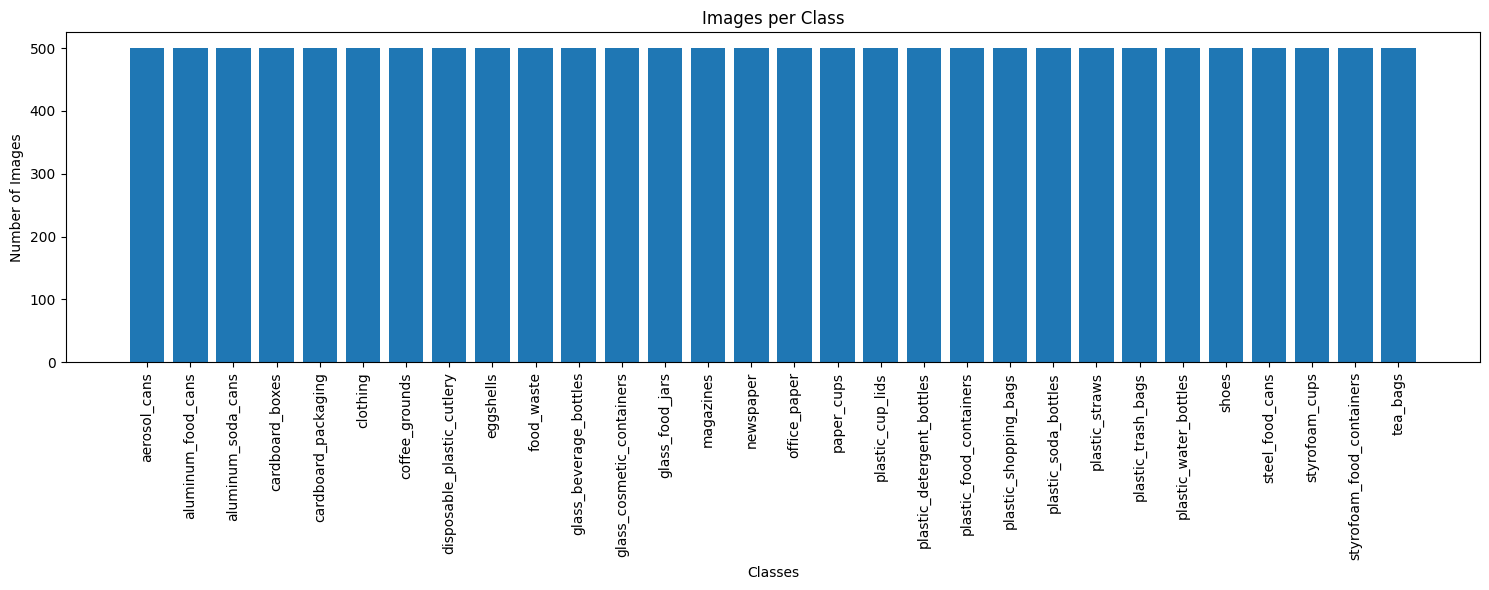

In [10]:
plt.figure(figsize=(15,6))

plt.bar(df["Class"], df["Number_of_Images"])

plt.xticks(rotation=90)

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Images per Class")

plt.tight_layout()
plt.show()

In [11]:
sample_class = classes[0]

sample_folder = os.path.join(dataset_path, sample_class, "real_world")

sample_image = os.listdir(sample_folder)[0]

sample_image_path = os.path.join(sample_folder, sample_image)

print(sample_image_path)

../data/images\aerosol_cans\real_world\Image_1.png


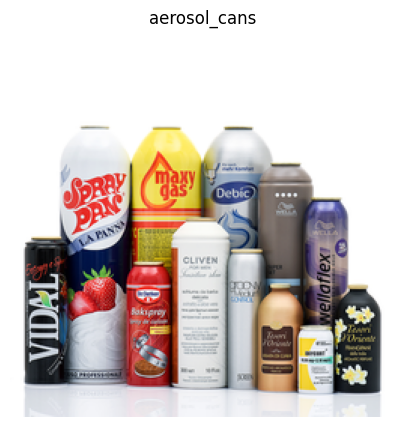

In [12]:
img = Image.open(sample_image_path)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.title(sample_class)
plt.axis("off")
plt.show()

In [13]:
print("Image Size:", img.size)
print("Image Mode:", img.mode)

Image Size: (256, 256)
Image Mode: RGB


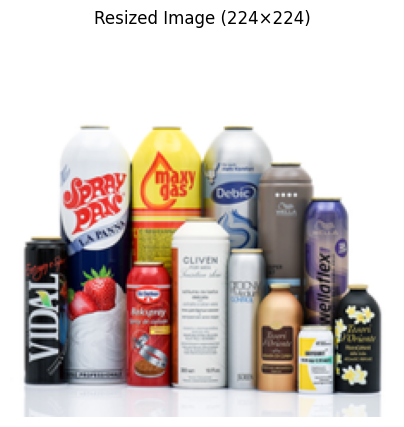

In [14]:
resized_img = img.resize((224, 224))

plt.figure(figsize=(5,5))
plt.imshow(resized_img)
plt.title("Resized Image (224×224)")
plt.axis("off")
plt.show()

In [15]:
print("Original Size:", img.size)
print("Resized Size:", resized_img.size)

Original Size: (256, 256)
Resized Size: (224, 224)


In [2]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import random_split, DataLoader

In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [4]:
dataset = datasets.ImageFolder(
    root="../data/images",
    transform=transform
)

print("Total images:", len(dataset))
print("Number of classes:", len(dataset.classes))
print(dataset.classes)

Total images: 15000
Number of classes: 30
['aerosol_cans', 'aluminum_food_cans', 'aluminum_soda_cans', 'cardboard_boxes', 'cardboard_packaging', 'clothing', 'coffee_grounds', 'disposable_plastic_cutlery', 'eggshells', 'food_waste', 'glass_beverage_bottles', 'glass_cosmetic_containers', 'glass_food_jars', 'magazines', 'newspaper', 'office_paper', 'paper_cups', 'plastic_cup_lids', 'plastic_detergent_bottles', 'plastic_food_containers', 'plastic_shopping_bags', 'plastic_soda_bottles', 'plastic_straws', 'plastic_trash_bags', 'plastic_water_bottles', 'shoes', 'steel_food_cans', 'styrofoam_cups', 'styrofoam_food_containers', 'tea_bags']


In [5]:
# Dataset sizes
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

print("Train:", train_size)
print("Validation:", val_size)
print("Test:", test_size)

# Split dataset
train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

Train: 10500
Validation: 2250
Test: 2250


In [6]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 329
Validation batches: 71
Test batches: 71


In [7]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
